# 08 · Weight initialization: zeros, random, Xavier and He

**Lecture:** *Weight Initialization in Neural Networks* (21-08-2026) · **Notes:** `../notes/08_weight_initialization.md`

> **Weight initialization** means choosing the weights' values **before training starts**. It is the optimiser's starting point. A bad start can make a network learn nothing at all.

In this notebook you will:
1. Recompute the lecture's Xavier and He numbers (Var 0.0133, σ ≈ 0.115; Var 0.02, σ ≈ 0.141) and check that the "uniform" versions have the same variance.
2. **See the symmetry problem:** start every weight equal, and the hidden neurons stay identical clones forever.
3. Push a signal through a 10-layer network and **watch it vanish or explode** with weights that are too small or too large, and stay stable with Xavier (tanh) and He (ReLU).
4. Train the same 8-hidden-layer network with four initializations and compare.
5. Learn what PyTorch does by default, and how to choose an initializer yourself.

Runs in under a minute on a CPU.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from sklearn.datasets import load_digits
torch.manual_seed(0)

## 1 · The lecture's formulas, in numbers

| | Normal: W ~ N(0, σ²) | Uniform: W ~ U(−a, a) |
|---|---|---|
| **Xavier / Glorot** (sigmoid, tanh) | σ² = 2 / (n_in + n_out) | a = √(6 / (n_in + n_out)) |
| **He / Kaiming** (ReLU family) | σ² = 2 / n_in | a = √(6 / n_in) |

Why the 6 in the uniform version? A uniform distribution on (−a, a) has variance **a²/3**, so a² = 3σ² gives the same variance: 3 × 2 = 6.

In [2]:
n_in, n_out = 100, 50
var_x = 2 / (n_in + n_out); var_h = 2 / n_in
print(f"Xavier normal: Var = 2/({n_in}+{n_out}) = {var_x:.4f}, sigma = {np.sqrt(var_x):.3f}")
print(f"He normal    : Var = 2/{n_in} = {var_h:.4f}, sigma = {np.sqrt(var_h):.3f}")
a_x = np.sqrt(6 / (n_in + n_out)); a_h = np.sqrt(6 / n_in)
print(f"Xavier uniform limit a = {a_x:.3f}  -> variance a^2/3 = {a_x ** 2 / 3:.4f} (same as normal)")
print(f"He uniform limit     a = {a_h:.3f}  -> variance a^2/3 = {a_h ** 2 / 3:.4f} (same as normal)")

# and PyTorch's built-in initializers produce exactly these scales
W = torch.empty(n_out, n_in)          # PyTorch stores Linear weights as (out, in)
for name, fn in [("xavier_normal_", nn.init.xavier_normal_), ("xavier_uniform_", nn.init.xavier_uniform_),
                 ("kaiming_normal_", lambda w: nn.init.kaiming_normal_(w, nonlinearity="relu")),
                 ("kaiming_uniform_", lambda w: nn.init.kaiming_uniform_(w, nonlinearity="relu"))]:
    fn(W); print(f"  nn.init.{name:<17} measured variance {W.var().item():.4f}   max |w| {W.abs().max().item():.3f}")

Xavier normal: Var = 2/(100+50) = 0.0133, sigma = 0.115
He normal    : Var = 2/100 = 0.0200, sigma = 0.141
Xavier uniform limit a = 0.200  -> variance a^2/3 = 0.0133 (same as normal)
He uniform limit     a = 0.245  -> variance a^2/3 = 0.0200 (same as normal)
  nn.init.xavier_normal_    measured variance 0.0131   max |w| 0.474
  nn.init.xavier_uniform_   measured variance 0.0133   max |w| 0.200
  nn.init.kaiming_normal_   measured variance 0.0206   max |w| 0.540
  nn.init.kaiming_uniform_  measured variance 0.0197   max |w| 0.245


The measured variances match the formulas (to sampling noise), and the uniform versions never exceed their limits a.

## 2 · Why not all zeros? The symmetry problem

Take a 2-layer network (64 → 8 hidden → 10) on the digits data. Start **every weight with the same value** and train it. Every hidden neuron receives the same inputs with the same weights, so it computes the same output and gets the same gradient, every single step.

In [3]:
d = load_digits()
X = torch.tensor(d.data / 16, dtype=torch.float32); y = torch.tensor(d.target)

def train_small(init_value=None, steps=300):
    torch.manual_seed(0)
    net = nn.Sequential(nn.Linear(64, 8), nn.Tanh(), nn.Linear(8, 10))
    if init_value is not None:
        for p in net.parameters(): nn.init.constant_(p, init_value)
    opt = torch.optim.SGD(net.parameters(), lr=0.5)
    for _ in range(steps):
        loss = F.cross_entropy(net(X), y); opt.zero_grad(); loss.backward(); opt.step()
    acc = (net(X).argmax(1) == y).float().mean().item()
    return net, loss.item(), acc

for label, v in [("all zeros", 0.0), ("all 0.01 (equal, not zero)", 0.01), ("random (PyTorch default)", None)]:
    net, L, acc = train_small(v)
    W1 = net[0].weight.detach()
    distinct = torch.unique(W1.round(decimals=6), dim=0).shape[0]
    print(f"{label:<28} loss {L:.3f}  train acc {acc:.1%}  distinct hidden neurons: {distinct} of 8")

all zeros                    loss 2.302  train acc 10.2%  distinct hidden neurons: 1 of 8


all 0.01 (equal, not zero)   loss 1.587  train acc 26.7%  distinct hidden neurons: 1 of 8
random (PyTorch default)     loss 0.129  train acc 97.8%  distinct hidden neurons: 8 of 8


With **equal** starting weights (zeros or 0.01), after 300 training steps the 8 hidden neurons are still **1 distinct neuron**: eight copies of the same feature, so the layer is effectively one neuron wide. Training accuracy: 10.2% (zeros) and 26.7% (all 0.01), against **97.8%** for random weights. (With all zeros it's even worse: tanh(0) = 0, so the output layer sees nothing, and the gradient reaching the first layer is exactly zero, so W1 never moves at all.)

Random initialization **breaks the symmetry**: the 8 neurons start different, receive different gradients, and learn 8 different features.

> **Biases can start at zero.** Once the weights are random, the neurons already differ, so zero biases cause no symmetry problem (the lecture says the same; PyTorch users often do `nn.init.zeros_(layer.bias)`).

## 3 · Too small, too large, just right: a signal through 10 layers

Feed 1,000 random inputs through 10 layers of width 256 **without any training** and measure the spread (standard deviation) of each layer's **pre-activation** z = x·W. If the spread shrinks towards 0, the signal **vanishes**; if it grows without bound, it **explodes**. Backpropagation multiplies by the same weights on the way back, so gradients behave the same way.

In [4]:
def forward_stds(sigma_fn, act, depth=10, width=256, n=1000, seed=0):
    g = torch.Generator().manual_seed(seed)
    x = torch.randn(n, width, generator=g)
    stds, sat = [], []
    for _ in range(depth):
        W = torch.randn(width, width, generator=g) * sigma_fn(width, width)
        z = x @ W
        stds.append(z.std().item()); x = act(z)
        sat.append((x.abs() > 0.99).float().mean().item())
    return stds, sat

configs = {
    "tanh, sigma = 0.01 (too small)": (lambda i, o: 0.01, torch.tanh),
    "tanh, sigma = 1 (too large)":    (lambda i, o: 1.0, torch.tanh),
    "tanh, Xavier":                    (lambda i, o: np.sqrt(2 / (i + o)), torch.tanh),
    "ReLU, sigma = 0.01 (too small)": (lambda i, o: 0.01, torch.relu),
    "ReLU, sigma = 1 (too large)":    (lambda i, o: 1.0, torch.relu),
    "ReLU, Xavier":                    (lambda i, o: np.sqrt(2 / (i + o)), torch.relu),
    "ReLU, He":                        (lambda i, o: np.sqrt(2 / i), torch.relu),
}
results = {k: forward_stds(*v) for k, v in configs.items()}
for k, (s, sat) in results.items():
    print(f"{k:<32} layer 1: {s[0]:>9.3g}   layer 5: {s[4]:>9.3g}   layer 10: {s[9]:>9.3g}")

tanh, sigma = 0.01 (too small)   layer 1:      0.16   layer 5:  0.000103   layer 10:  1.06e-08
tanh, sigma = 1 (too large)      layer 1:        16   layer 5:      15.6   layer 10:      15.6
tanh, Xavier                     layer 1:         1   layer 5:     0.358   layer 10:     0.238
ReLU, sigma = 0.01 (too small)   layer 1:      0.16   layer 5:  2.35e-05   layer 10:  3.58e-10
ReLU, sigma = 1 (too large)      layer 1:        16   layer 5:  2.35e+05   layer 10:  3.58e+10
ReLU, Xavier                     layer 1:         1   layer 5:     0.224   layer 10:    0.0326
ReLU, He                         layer 1:      1.42   layer 5:      1.27   layer 10:      1.04


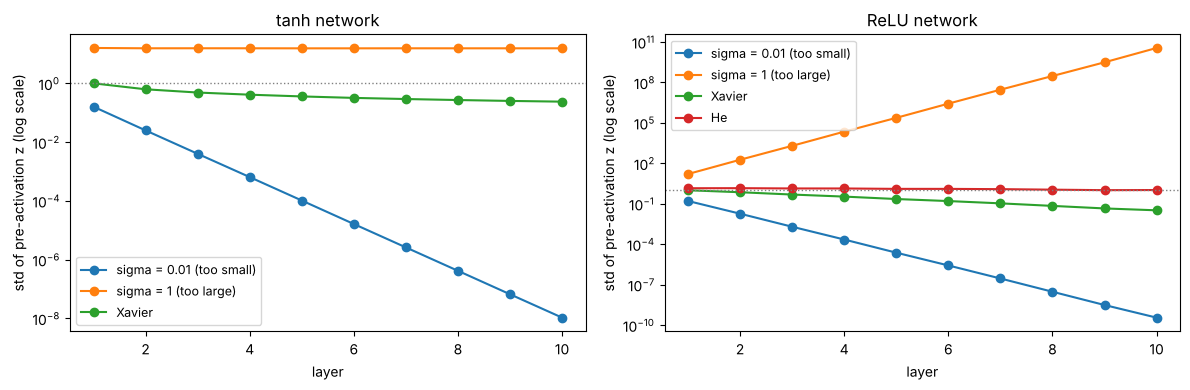

tanh with sigma = 1: fraction of activations with |tanh| > 0.99 (saturated), layers 1-3: ['87%', '87%', '87%']


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for k, (s, _) in results.items():
    ax = axes[0] if k.startswith("tanh") else axes[1]
    ax.semilogy(range(1, 11), s, "o-", label=k.split(", ")[1])
for ax, t in zip(axes, ["tanh network", "ReLU network"]):
    ax.set_title(t); ax.set_xlabel("layer"); ax.set_ylabel("std of pre-activation z (log scale)")
    ax.axhline(1, color="grey", ls=":", lw=1); ax.legend(fontsize=9)
plt.tight_layout(); plt.show()
print("tanh with sigma = 1: fraction of activations with |tanh| > 0.99 (saturated), layers 1-3:",
      [f"{v:.0%}" for v in results["tanh, sigma = 1 (too large)"][1][:3]])

**What the measurements show:**
- **Too small (σ = 0.01):** the spread shrinks by roughly 6× (tanh) and 9× (ReLU) per layer and is essentially zero by layer 10: **vanishing**.
- **Too large, ReLU (σ = 1):** the spread grows by about 11× per layer, reaching about 36 billion by layer 10: **exploding**.
- **Too large, tanh (σ = 1):** the pre-activations are huge, but tanh squashes them, and most activations sit at ±1, **saturated**, where tanh's slope is ≈ 0. The forward signal doesn't explode, but the gradients through those neurons **vanish**.
- **He with ReLU:** the spread stays between 1.0 and 1.4 through all 10 layers (He's factor 2 exactly compensates ReLU zeroing half the values).
- **Xavier with ReLU:** shrinks steadily, about 0.7× per layer, because Xavier doesn't include ReLU's factor 2. That's why the lecture's rule is **ReLU → He**.
- **Xavier with tanh:** shrinks slowly. For tanh, Xavier is the standard choice and far better than the bad options; the decay comes from tanh flattening values that aren't tiny.

Why σ = 0.01 is "small" depends on width: each z sums 256 terms, so its spread is σ·√256 ≈ 16σ times the input's. Xavier and He pick σ **from the layer size** precisely to cancel that √n.

## 4 · Does it matter for training? Same network, four starts

An 8-hidden-layer ReLU network (width 128) on the digits, plain SGD (lr 0.05, batch 64, 30 epochs). Only the initialization changes.

In [6]:
def make_deep(init_fn, depth=8, width=128):
    torch.manual_seed(0); layers, i = [], 64
    for _ in range(depth):
        L = nn.Linear(i, width); init_fn(L.weight); nn.init.zeros_(L.bias); layers += [L, nn.ReLU()]; i = width
    L = nn.Linear(i, 10); init_fn(L.weight); nn.init.zeros_(L.bias); layers.append(L)
    return nn.Sequential(*layers)

inits = {
    "N(0, 0.01²)  too small": lambda w: nn.init.normal_(w, 0, 0.01),
    "N(0, 1)      too large": lambda w: nn.init.normal_(w, 0, 1.0),
    "Xavier normal":          nn.init.xavier_normal_,
    "He normal":              lambda w: nn.init.kaiming_normal_(w, nonlinearity="relu"),
}
histories = {}
for name, f in inits.items():
    net = make_deep(f); opt = torch.optim.SGD(net.parameters(), lr=0.05)
    hist = []
    for ep in range(30):
        perm = torch.randperm(len(X))
        for b in range(0, len(X), 64):
            idx = perm[b:b + 64]
            loss = F.cross_entropy(net(X[idx]), y[idx]); opt.zero_grad(); loss.backward(); opt.step()
        with torch.no_grad():
            out = net(X); hist.append((F.cross_entropy(out, y).item(), (out.argmax(1) == y).float().mean().item()))
    histories[name] = hist
    print(f"{name:<24} after epoch 1: loss {hist[0][0]:.3f} acc {hist[0][1]:.1%}   after 30: loss {hist[-1][0]:.4f} acc {hist[-1][1]:.1%}")

N(0, 0.01²)  too small   after epoch 1: loss 2.303 acc 10.1%   after 30: loss 2.3025 acc 10.1%


N(0, 1)      too large   after epoch 1: loss nan acc 9.9%   after 30: loss nan acc 9.9%


Xavier normal            after epoch 1: loss 2.279 acc 20.1%   after 30: loss 0.0512 acc 99.1%


He normal                after epoch 1: loss 1.618 acc 54.7%   after 30: loss 0.0024 acc 100.0%


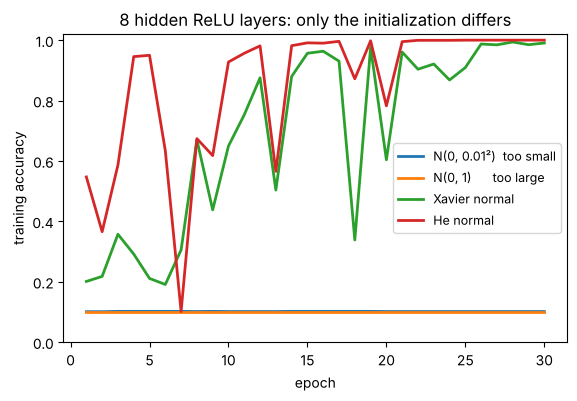

In [7]:
plt.figure(figsize=(6.5, 4))
for name, hist in histories.items():
    acc = [a for _, a in hist]
    plt.plot(range(1, 31), acc, lw=2, label=name)
plt.xlabel("epoch"); plt.ylabel("training accuracy"); plt.ylim(0, 1.02)
plt.title("8 hidden ReLU layers: only the initialization differs"); plt.legend(fontsize=9); plt.show()

- **Too small:** stuck at chance (≈ 10%, loss 2.30 = ln 10) for all 30 epochs. The signal and the gradients vanish before reaching the early layers, so nothing learns.
- **Too large:** the loss becomes `nan` (numbers overflow) and the network never recovers.
- **Xavier:** learns, but after a slow start (20.1% after epoch 1, 99.1% after 30).
- **He:** learns fastest (54.7% after epoch 1) and reaches the lowest loss (0.0024, 100% training accuracy), as expected for ReLU.

Same architecture, same data, same optimiser: initialization alone decides between "doesn't learn", "crashes" and "works".

> In practice, **Batch Normalization** (chapter 05) and residual connections make deep networks much less sensitive to initialization. But the starting scale still matters, and every framework picks one for you.

## 5 · What does PyTorch do by default?

`nn.Linear` and `nn.Conv2d` initialize weights with `kaiming_uniform_(a=√5)`, which works out to **U(−1/√n_in, 1/√n_in)**, variance **1/(3·n_in)**. That's smaller than He's 2/n_in (by a factor of 6), a historical choice. For shallow networks it's fine; for deep plain ReLU stacks you may want to set He explicitly.

In [8]:
layer = nn.Linear(100, 50)
w = layer.weight.detach()
print(f"default nn.Linear(100, 50): max |w| = {w.abs().max():.4f} (1/sqrt(100) = {1 / np.sqrt(100):.4f}),"
      f" variance = {w.var():.5f} (1/(3*100) = {1 / 300:.5f})")
print(f"He would use variance 2/100 = 0.02, i.e. {0.02 / (1 / 300):.0f}x larger")

# how to set it yourself
def init_he(m):
    if isinstance(m, nn.Linear):
        nn.init.kaiming_normal_(m.weight, nonlinearity="relu")
        nn.init.zeros_(m.bias)
model = nn.Sequential(nn.Linear(784, 256), nn.ReLU(), nn.Linear(256, 10))
model.apply(init_he)       # .apply visits every sub-module
print(f"after model.apply(init_he): first-layer weight std = {model[0].weight.std():.4f} (sqrt(2/784) = {np.sqrt(2 / 784):.4f})")

default nn.Linear(100, 50): max |w| = 0.0999 (1/sqrt(100) = 0.1000), variance = 0.00337 (1/(3*100) = 0.00333)
He would use variance 2/100 = 0.02, i.e. 6x larger
after model.apply(init_he): first-layer weight std = 0.0505 (sqrt(2/784) = 0.0505)


## 6 · Summary: choosing an initializer

| Activation in the hidden layers | Use | PyTorch |
|---|---|---|
| sigmoid, tanh | **Xavier / Glorot** | `nn.init.xavier_normal_` or `xavier_uniform_` |
| ReLU, Leaky ReLU, PReLU | **He / Kaiming** | `nn.init.kaiming_normal_(w, nonlinearity="relu")` |
| biases | zeros | `nn.init.zeros_` |

**The chain the lecture draws:** initialization sets the **scale of the weights** → which sets the **scale of activations** (forward) and **derivatives** (backward) → too small vanishes, too large explodes → which decides whether the weight updates do anything useful.

Initialization happens **once, before** training. It is **not** an optimiser.

## ✅ Check yourself
1. A layer has n_in = 200, n_out = 100. Xavier normal σ? He normal σ? *(√(2/300) ≈ 0.082; √(2/200) = 0.1)*
2. He uniform limit for n_in = 150? *(√(6/150) = 0.2)*
3. What exactly goes wrong if all hidden weights start equal? *(every hidden neuron computes the same thing and gets the same gradient, so they stay identical: section 2 measured 1 distinct neuron out of 8)*
4. Why does He use 2/n_in instead of 1/n_in? *(ReLU zeroes about half its inputs, halving the signal's power; the factor 2 restores it)*
5. Your 10-layer ReLU network's loss stays at 2.30 on a 10-class problem from the first epoch. Likely cause? *(weights too small: vanishing signal; the loss ln 10 means uniform guessing)*
6. Is it OK to initialize biases to zero? *(yes, as long as the weights are random)*